# Mg–Ca phase diagram construction

Reproduces `MgCa_Phasediagram_Construction_Manual.svg` with the current landau API:

- **a)** semigrand potential $\phi(\Delta\mu)$ of all phases at 800 K — `ld.plot.plot_1d_mu_phase_diagram`
- **b)** excess free energy $f(c)$ with common tangents at 800 K — `ld.plot.plot_excess_free_energy`
- **c)** the resulting $T$–$c$ phase diagram, 800/900/1000 K cuts marked — `ld.plot.plot_phase_diagram`

Data: calphy/ACE free energies in `MgCaFreeEnergies.pckl.gz` (from the landau repo, `notebooks/MgCa`). The liquid is rebuilt from the raw
line-phase free energies with `FastInterpolatingPhase` (the pickled `InterpolatingPhase` is deprecated).

Writes `MgCa_Phasediagram_Construction_landau.svg` and `.png` (transparent) next to the notebook.

## Setup

In [1]:
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import landau as ld

warnings.simplefilter("ignore", DeprecationWarning)

/home/pmrv/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/claude-1000/matplotlib-l63d0de9 because there was an issue with the default path (/home/pmrv/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [2]:
DATA = "MgCaFreeEnergies.pckl.gz"
OUT = "MgCa_Phasediagram_Construction_landau.svg"

T_SLICE = 800  # temperature of panels a) and b)
T_CUTS = [800, 900, 1000]  # transitions marked in c)
T_RANGE = (700, 1100)
MU_RANGE = (-1.1, -0.1)

MG, MG2CA, CA, LIQ = "hcp Mg", "Mg$_2$Ca", "bcc Ca", "liquid"
PHASE_COLOR = {MG: "#a1c9f4", MG2CA: "#ffb482", CA: "#ff9f9b", LIQ: "#debb9b"}  # seaborn pastel: c) fills
LINE_COLOR = {MG: "#4878d0", MG2CA: "#ee854a", CA: "#d65f5f", LIQ: "#8c613c"}  # seaborn muted: a) b) lines
MIN_C_WIDTH = 0.005  # line-phase width in c); landau inflates *every* polygon by half of this
CUT_MARKER = {800: "D", 900: "o", 1000: "o"}

FIGSIZE = (10.5, 7.5)  # inches
FONTSIZE = 15
DPI = 150  # PNG: 1575 x 1125 px

## Phases

`fcc Ca` is never stable here, so `bcc Ca` is the Ca phase.

In [3]:
raw = pd.read_pickle(DATA)
raw = raw[raw.phase != "fcc Ca"]


def line(r):
    return ld.phases.TemperatureDependentLinePhase(
        r.phase, r.composition, r.temperature, r.free_energy, interpolator=ld.interpolate.SGTE(4)
    )


solids = [line(r) for _, r in raw[raw.phase != LIQ].iterrows()]
liquid = ld.phases.FastInterpolatingPhase(LIQ, [line(r) for _, r in raw[raw.phase == LIQ].iterrows()])
phases = {p.name: p for p in solids + [liquid]}
phases

{'hcp Mg': TemperatureDependentLinePhase(name='hcp Mg', fixed_concentration=0.0, temperatures=array([ 300.        ,  300.00420006,  300.00840024, ...,  999.90667538,
         999.95333551, 1000.        ], shape=(50001,)), free_energies=array([-1.52251546, -1.52251687, -1.52251828, ..., -1.89900584,
        -1.89903773, -1.89906963], shape=(50001,)), interpolator=SGTE(nparam=4)),
 'bcc Ca': TemperatureDependentLinePhase(name='bcc Ca', fixed_concentration=1.0, temperatures=array([ 300.        ,  300.00461546,  300.00923106, ..., 1299.82798938,
        1299.91463891, 1300.0013    ], shape=(50001,)), free_energies=array([-1.93428445, -1.93428657, -1.93428869, ..., -2.64088933,
        -2.64096458, -2.64103983], shape=(50001,)), interpolator=SGTE(nparam=4)),
 'Mg$_2$Ca': TemperatureDependentLinePhase(name='Mg$_2$Ca', fixed_concentration=0.3333333333333333, temperatures=array([ 300.        ,  300.00420006,  300.00840024, ...,  999.90667538,
         999.95333551, 1000.        ], shape=(50001

## Calculate

In [4]:
df_phi = ld.calculate.calc_phase_diagram(
    phases.values(), Ts=[T_SLICE], mu=np.linspace(*MU_RANGE, 200), keep_unstable=True
)
df_f = ld.calculate.calc_phase_diagram(phases.values(), Ts=[T_SLICE], mu=200, keep_unstable=True)
df_full = ld.calculate.calc_phase_diagram(phases.values(), Ts=np.linspace(*T_RANGE, 50), mu=200)
df_cuts = pd.concat(
    [ld.calculate.calc_phase_diagram(phases.values(), Ts=[T], mu=200) for T in T_CUTS], ignore_index=True
)

In [5]:
def transitions(df, T):
    """Coexisting phase rows at exactly temperature T, one group per mu."""
    b = df.query("locus == 'boundary' and T == @T").sort_values(["mu", "c"])
    return [g for _, g in b.groupby("mu")]


pd.concat([g for T in T_CUTS for g in transitions(df_cuts, T)])[["T", "phase", "mu", "c"]]

,T,phase,mu,c
200,800,hcp Mg,-0.901350,0.000000
201,800,liquid,-0.901350,0.062036
202,800,liquid,-0.769945,0.153952
203,800,Mg$_2$Ca,-0.769945,0.333333
204,800,Mg$_2$Ca,-0.383723,0.333333
205,800,liquid,-0.383723,0.544059
206,800,liquid,-0.219424,0.789715
207,800,bcc Ca,-0.219424,1.000000
408,900,liquid,-0.678721,0.243831
409,900,Mg$_2$Ca,-0.678721,0.333333


## Plot helpers

In [6]:
def _plain(label):
    """landau bolds mathtext in its labels (Mg$\\mathbf{_2}$Ca); strip that to compare names."""
    return re.sub(r"\\mathbf\{([^}]*)\}", r"\1", label)


def phase_texts(ax, names):
    return [t for t in ax.texts if _plain(t.get_text()) in names]


def rotate_phase_labels(ax, names):
    """Turn landau's inline phase labels on ax vertical."""
    for t in phase_texts(ax, names):
        t.set(rotation=90, rotation_mode="anchor")

## Panels

In [7]:
def panel_phi(ax, df):
    # seaborn takes its hue colours (sorted phase names) from the rc colour cycle
    cycle = plt.cycler(color=[LINE_COLOR[n] for n in sorted(phases)])
    with plt.rc_context({"axes.prop_cycle": cycle, "lines.linewidth": 2}):
        ld.plot.plot_1d_mu_phase_diagram(df, ax=ax, ylim=(-2.1, -1.6), mark_transitions=False, element="Ca")
    for g in transitions(df, T_SLICE):
        ax.scatter(g.mu.iloc[0], g.phi.iloc[0], marker="D", s=45, color="k", edgecolor="w", lw=0.8, zorder=5)
    for t in phase_texts(ax, phases):  # top labels: vertical, hanging down from the top edge
        t.set(rotation=90, rotation_mode="anchor", ha="right", va="center")
    ax.set_xlim(*MU_RANGE)
    ax.set_ylabel(r"$\phi = f - \Delta\mu\,c$ [eV/atom]")
    ax.set_title(f"T = {T_SLICE} K")


def panel_f(ax, df):
    plt.sca(ax)  # single-T plot_excess_free_energy draws onto the current axes
    ld.plot.plot_excess_free_energy(df, color_override=LINE_COLOR, element="Ca")
    rotate_phase_labels(ax, phases)
    ax.set_xlim(-0.03, 1.03)
    ax.set_ylabel(r"$f_\mathrm{excess}$ [eV/atom]")
    ax.set_title(f"T = {T_SLICE} K")


def panel_diagram(ax, df_full, df_cuts):
    ld.plot.plot_phase_diagram(
        df_full, element="Ca", color_override=PHASE_COLOR, legend=False, triplepoints=True, transition_temperatures=True, ax=ax,
        poly_method=ld.poly.SegmentFastTsp(min_c_width=MIN_C_WIDTH),
    )
    for T in T_CUTS:
        for g in transitions(df_cuts, T):
            for _, r in g.iterrows():
                ax.scatter(r.c, T, marker=CUT_MARKER[T], s=45, color=PHASE_COLOR[r.phase],
                           edgecolor="k", lw=0.8, zorder=10, clip_on=False)
    ax.set_xlim(0, 1)
    ax.set_ylim(*T_RANGE)
    # vertical labels beside each line-phase strip
    for x, ha, n in [(0.012, "left", MG), (0.322, "right", MG2CA), (0.988, "right", CA)]:
        ax.text(x, 733, n, rotation=90, ha=ha, va="bottom", fontsize=FONTSIZE - 2)
    ax.text(0.65, 1000, "liquid", ha="center", va="center")

## Figure

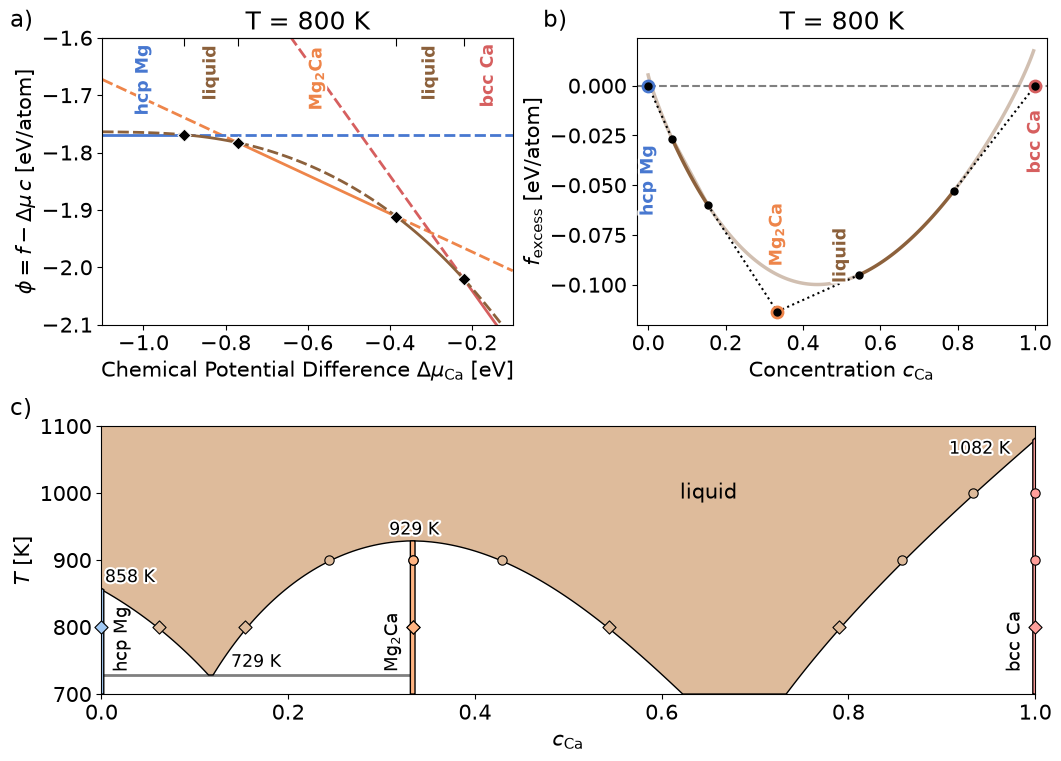

In [8]:
plt.style.use("default")
plt.rcParams.update({"font.size": FONTSIZE, "svg.fonttype": "none"})
fig = plt.figure(figsize=FIGSIZE, layout="constrained")
top, bottom = fig.subfigures(2, 1, height_ratios=[1, 0.95])
ax_a, ax_b = top.subplots(1, 2)
ax_c = bottom.subplots()

panel_phi(ax_a, df_phi)
panel_f(ax_b, df_f)
panel_diagram(ax_c, df_full, df_cuts)

for ax, lab in zip((ax_a, ax_b, ax_c), "abc"):
    ax.annotate(f"{lab})", xy=(0, 1), xycoords="axes fraction", xytext=(-50, 4), textcoords="offset points",
                ha="right", va="bottom", fontsize=FONTSIZE + 1.5)

fig.savefig(OUT)
fig.savefig(OUT.replace(".svg", ".png"), dpi=DPI, transparent=True)